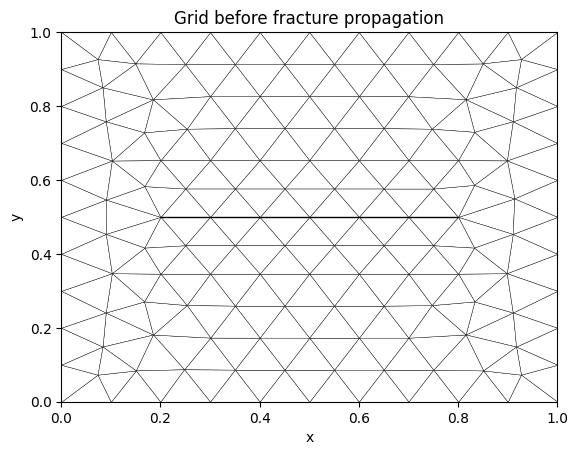

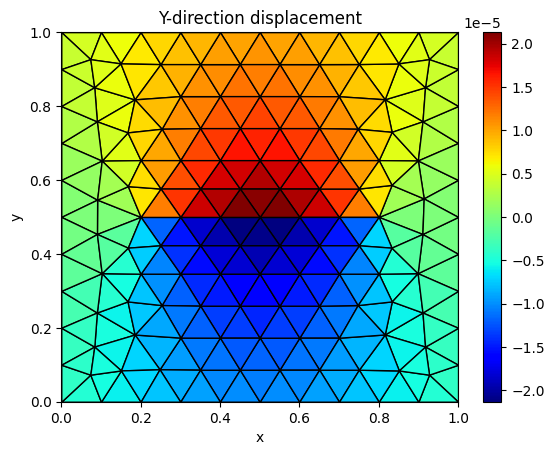

Grid Tensor grid in 1 dimensions.
Number of cells 6
Number of faces 7
Number of nodes 7
 has no 'u' defined in TIME_STEP_SOLUTIONS
Displacement jump n value:  [3.83724930e-05 3.83834879e-05]
Displacement jump n r:  [0.15 0.15]
Displacement jump t value:  [ 1.72312493e-10 -1.50939371e-09]
Displacement jump t r:  [0.15 0.15]

Displacement jump n value 1:  [2.52987701e-05 2.53371828e-05]
Displacement jump n value 2:  [4.41323437e-05 4.41347922e-05]
Displacement jump n r 1:  [0.05 0.05]
Displacement jump n r 2:  [0.25 0.25]
The order of singularity: [0.34573383879676184, 0.3448256142263037]
The order average of singularity: 0.34527972651153277
Relative L2 error: 0.30944187981793086
Relative error per tip: [0.30853232 0.31034877]


Displacement jump n value 1:  [4.41323437e-05 4.41347922e-05]
Displacement jump n value 2:  [4.34421717e-05 4.34747113e-05]
Displacement jump n r 1:  [0.25 0.25]
Displacement jump n r 2:  [0.225 0.225]
The order of singularity: [0.1496031375348744, 0.143023134180

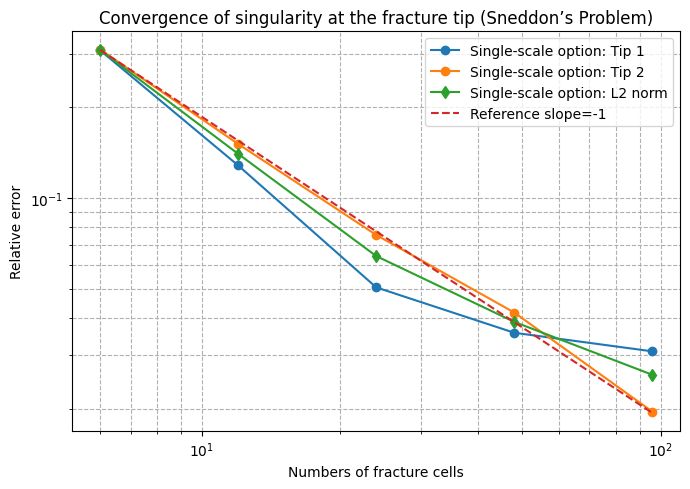

Grid: [ 6 12 24 48 96]
Numerical results: [0.30944188 0.13989783 0.06408631 0.03876361 0.02588229]


Displacement jump n value 1:  [4.41323437e-05 4.41347922e-05]
Displacement jump n value 2:  [4.34421717e-05 4.34747113e-05]
Displacement jump n r 1:  [0.25 0.25]
Displacement jump n r 2:  [0.225 0.225]
The order of singularity: [0.1496031375348744, 0.14302313418094106]
The order average of singularity: 0.14631313585790773
Relative L2 error: 0.707404331277951
Relative error per tip: [0.70079372 0.71395373]
Number of fracture cells: 6


Displacement jump n value 1:  [4.34421717e-05 4.34747113e-05]
Displacement jump n value 2:  [3.99557584e-05 4.00062739e-05]
Displacement jump n r 1:  [0.225 0.225]
Displacement jump n r 2:  [0.1625 0.1625]
The order of singularity: [0.2570746982285915, 0.2554929539953996]
The order average of singularity: 0.25628382611199557
Relative L2 error: 0.48743491419188595
Relative error per tip: [0.4858506  0.48901409]
Number of fracture cells: 12


Displacement ju

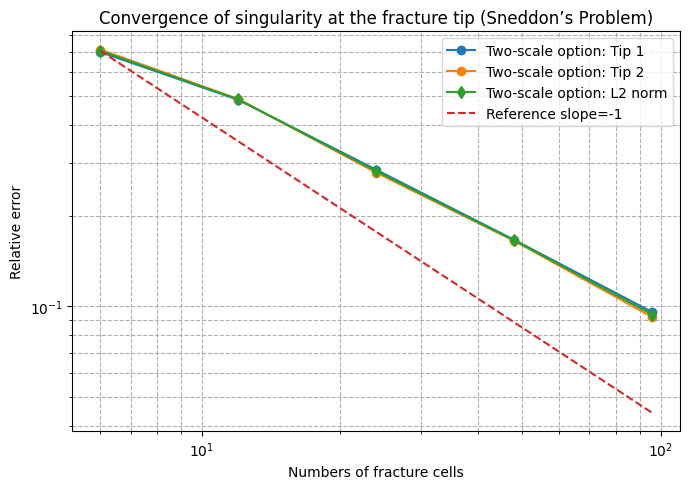

Grid: [ 6 12 24 48 96]
Numerical results: [0.70740433 0.48743491 0.28131847 0.16558775 0.0938344 ]


In [ ]:
"""
Evaluate the singularity order (exponent) at fracture tips within a simulation domain for Sneddon's problem.

Currently, the script only supports a single fracture with two fracture tips.

Features: 
 - Provide two options of selecting fracture cell locations (cell centers) along the fracture for evaluating
   singularity order (exponent): 

        Single-scale option: evaluate singularity at the same grid refinement level by two cell centers (i and j)
        near the fracture tip. It is noted that cells can be flexibly selected. We use the following as an 
        example: the cell center i is selected at the fracture tip cell (r_i=h/2), while the cell center j can be 
        movable to the third cell closest to the frature tip (r_j=5*h/2).

        Two-scale option: cell centers i and j, whose distance are r_i and r_j, are movable and selected from fine and 
        coarse grids, respectively. If the refinement levels of coarse and fine grids are k_c and k_f, where k_f=k_c+1, 
        the distance from cell center j to the fracture tip face in coarse grids is (4*k_c+1)*h_c/2 and the distance from 
        cell center j in fine grids is (4*k_f+1)*h_f/2. 

 - Perform both single-scale and two-scale convergence curve analysis. 
   The single-scale analysis evaluates convergence only with respect to mesh size (cell size: h),
   while the two-scale analysis involves coarse and fine models.

"""
from __future__ import annotations

import porepy as pp
import numpy as np

import math
import matplotlib.pyplot as plt
import scipy.sparse as sps

from tests.functional.setups.manu_sneddon_2d import ManuSneddonModel2d
from fracture import FractureDisplacementJump
from fracture import ComputeSingularityErrorForModel

a = 0.3
poi = 0.25
shear_modulus = 1.0
lam = 2 * shear_modulus * poi / (1 - 2 * poi)

params = {
    "prepare_simulation": True,
    "material_constants": {"solid": pp.SolidConstants(shear_modulus=shear_modulus, lame_lambda=lam)},
    "a": a,
    "domain_size": 1.0,
    "p0": 1e-4,
    "poi": poi,
    "meshing_arguments": {"cell_size": 0.1},
    "grid_type": "simplex",
    "theta_rad": math.radians(90 - 0),
    "num_bem_segments": 1000,
    "error_exclusion_zone_fracture_tips": 0.1,
}

# Chose the sampling option for fracture cells 
# params.update({
#     "sampling": {"mode": "refinement", "level": 1}
# })

params.update({
    "sampling": {"mode": "fixed", "steps": 1}
})

model = ManuSneddonModel2d(params=params)
pp.run_time_dependent_model(model)

# Plot
pp.plot_grid(
    model.mdg,
    rgb=[1, 1, 1],
    figsize=(8,8), 
    plot_2d=True,           
    linewidth=0.3,
    alpha=1.0,
    title="Grid before fracture propagation"
)
plt.show()

# 2D displacement plot
for g, data in model.mdg.subdomains(return_data=True):
    # get 'u'（t=0 by default）
    u = data.get(pp.TIME_STEP_SOLUTIONS, {}).get("u", {}).get(0, None)

    if u is not None:
        # get the displacement y along the y direction
        y_disp = u[1::2]

        # plot
        pp.plot_grid(
            g,
            cell_value=y_disp,
            plot_2d=True,
            title="Y-direction displacement"
        )
        plt.show()
    else:
        print(f"Grid {g} has no 'u' defined in TIME_STEP_SOLUTIONS")

jumpmodel = FractureDisplacementJump(model)

u_jump_n, r_n = jumpmodel.extract_sampling_normal_jump()
u_jump_t, r_t = jumpmodel.extract_sampling_tangential_jump()

print("Displacement jump n value: ", u_jump_n)
print("Displacement jump n r: ", r_n)

print("Displacement jump t value: ", u_jump_t)
print("Displacement jump t r: ", r_t)

# test the single-scale option for convergence error at one step
h = 0.1
params["meshing_arguments"] = {"cell_size": h}
params["sampling"] = {"mode": "fixed", "steps": 1}
model = ManuSneddonModel2d(params=params)
pp.run_time_dependent_model(model)
comp = ComputeSingularityErrorForModel(model)
steps_pair=(0, 2)
rel_l2_error_ave, rel_error_per_tip = comp.single_scale_option_normal(steps_pair)
print("Relative L2 error:", rel_l2_error_ave)
print("Relative error per tip:", rel_error_per_tip)

# test the two-scale option for convergence error at one step
h_coarse = 0.1
refinement_level = 1
params["meshing_arguments"] = {"cell_size": h_coarse}
params["sampling"] = {"mode": "refinement", "level": refinement_level}
model_coarse = ManuSneddonModel2d(params=params)
pp.run_time_dependent_model(model_coarse)
comp_coarse = ComputeSingularityErrorForModel(model_coarse)

h_fine = h_coarse / 2.0
params["meshing_arguments"] = {"cell_size": h_fine}
params["sampling"] = {"mode": "refinement", "level": refinement_level+1}
model_fine = ManuSneddonModel2d(params=params)
pp.run_time_dependent_model(model_fine)
jumpmodel_fine = FractureDisplacementJump(model_fine)

rel_l2_error_ave, rel_error_per_tip = comp_coarse.two_scale_option_normal(jumpmodel_fine)

print("Relative L2 error:", rel_l2_error_ave)
print("Relative error per tip:", rel_error_per_tip)

# test the single-scale option for convergence curves
cell_sizes = [0.1, 0.05, 0.025, 0.0125, 0.00625]
error_ave_set = []
error_per_tip_set = []
num_frac_cells_set = []
for h in cell_sizes:
    params["meshing_arguments"] = {"cell_size": h}
    # this steps value is only for keyword initialization 
    # and does not work for the simulation results 
    params["sampling"] = {"mode": "fixed", "level": 1}
    model = ManuSneddonModel2d(params=params)
    pp.run_time_dependent_model(model)
    comp = ComputeSingularityErrorForModel(model)
    # This steps_pair will work for the keywords: params["sampling"] = {"mode": "fixed", "steps": X}
    steps_pair=(0, 2)
    rel_l2_error_ave, rel_error_per_tip = comp.single_scale_option_normal(steps_pair)
    print("Relative L2 error:", rel_l2_error_ave)
    print("Relative error per tip:", rel_error_per_tip)
    error_ave_set.append(rel_l2_error_ave)
    error_per_tip_set.append(rel_error_per_tip)

    # Number of fracture cells
    num_frac_cells = comp.get_number_of_fracture_cells()
    print("Number of fracture cells:", num_frac_cells)
    num_frac_cells_set.append(num_frac_cells)

# Plot convergence
hs = np.array(cell_sizes)
err_ave = np.array(error_ave_set)
err_per_tip = np.array(error_per_tip_set)
fs = np.array(num_frac_cells_set)

plt.figure(figsize=(7, 5))
plt.loglog(fs, err_per_tip[:, 0], 'o-', label="Single-scale option: Tip 1")
plt.loglog(fs, err_per_tip[:, 1], 'o-', label="Single-scale option: Tip 2")
plt.loglog(fs, err_ave, 'd-', label="Single-scale option: L2 norm")
plt.loglog(fs, err_ave[0] * (fs[0] / fs), '--', label="Reference slope=-1")
plt.xlabel("Numbers of fracture cells")
plt.ylabel("Relative error")
plt.title("Convergence of singularity at the fracture tip (Sneddon’s Problem)")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.show()

print("Grid:", fs)
print("Numerical results:", err_ave)

# test the two-scale option for convergence curves
cell_sizes = [0.1, 0.05, 0.025, 0.0125, 0.00625]
error_ave_set = []
error_per_tip_set = []
num_frac_cells_set = []
refinement_level = 1
for h in cell_sizes:
    h_coarse = h
    params["meshing_arguments"] = {"cell_size": h_coarse}
    params["sampling"] = {"mode": "refinement", "level": refinement_level}
    model_coarse = ManuSneddonModel2d(params=params)
    pp.run_time_dependent_model(model_coarse)
    comp_coarse = ComputeSingularityErrorForModel(model_coarse)

    h_fine = h_coarse / 2.0
    params["meshing_arguments"] = {"cell_size": h_fine}
    params["sampling"] = {"mode": "refinement", "level": refinement_level+1}
    model_fine = ManuSneddonModel2d(params=params)
    pp.run_time_dependent_model(model_fine)
    jumpmodel_fine = FractureDisplacementJump(model_fine)

    rel_l2_error_ave, rel_error_per_tip = comp_coarse.two_scale_option_normal(jumpmodel_fine)

    print("Relative L2 error:", rel_l2_error_ave)
    print("Relative error per tip:", rel_error_per_tip)
    error_ave_set.append(rel_l2_error_ave)
    error_per_tip_set.append(rel_error_per_tip)

    # Number of fracture cells by use of the coarse model
    num_frac_cells = comp_coarse.get_number_of_fracture_cells()
    print("Number of fracture cells:", num_frac_cells)
    num_frac_cells_set.append(num_frac_cells)

    refinement_level = refinement_level + 1

# Plot convergence
hs = np.array(cell_sizes)
err_ave = np.array(error_ave_set)
err_per_tip = np.array(error_per_tip_set)
fs = np.array(num_frac_cells_set)

plt.figure(figsize=(7, 5))
plt.loglog(fs, err_per_tip[:, 0], 'o-', label="Two-scale option: Tip 1")
plt.loglog(fs, err_per_tip[:, 1], 'o-', label="Two-scale option: Tip 2")
plt.loglog(fs, err_ave, 'd-', label="Two-scale option: L2 norm")
plt.loglog(fs, err_ave[0] * (fs[0] / fs), '--', label="Reference slope=-1")
plt.xlabel("Numbers of fracture cells")
plt.ylabel("Relative error")
plt.title("Convergence of singularity at the fracture tip (Sneddon’s Problem)")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.show()

print("Grid:", fs)
print("Numerical results:", err_ave)
